## 文档向量化
- `向量`：文本的数学表示，文本->向量
- `嵌入模型`：实现文本向量化的模型，将文本转化为固定维度的向量
- `为什么要使用嵌入模型做文档向量化？`通过计算向量的相似度来确定语义相关性，使语义相近的文本在向量空间中距离更近

### 常见嵌入模型

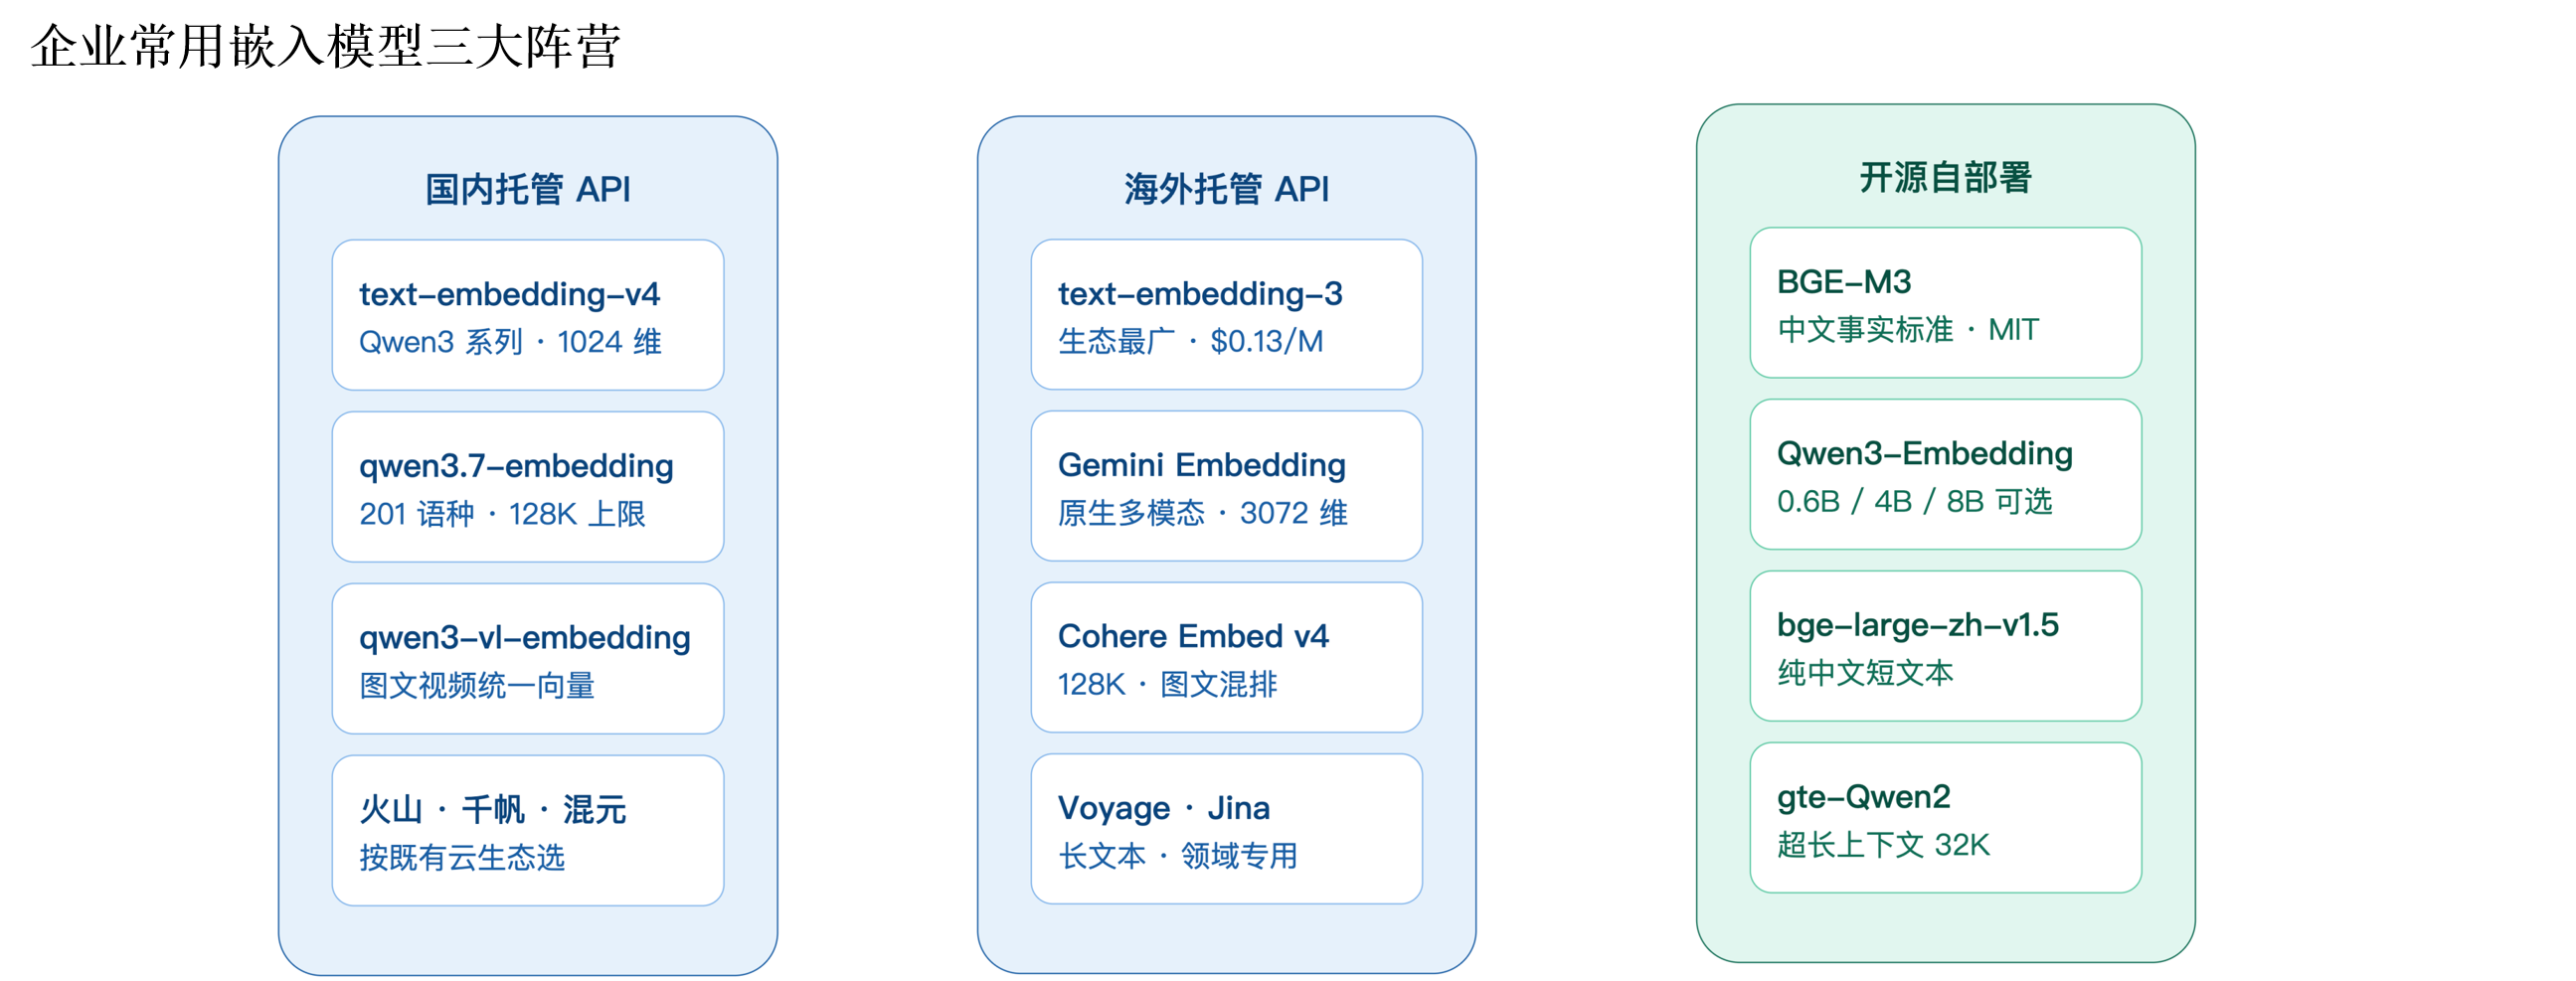

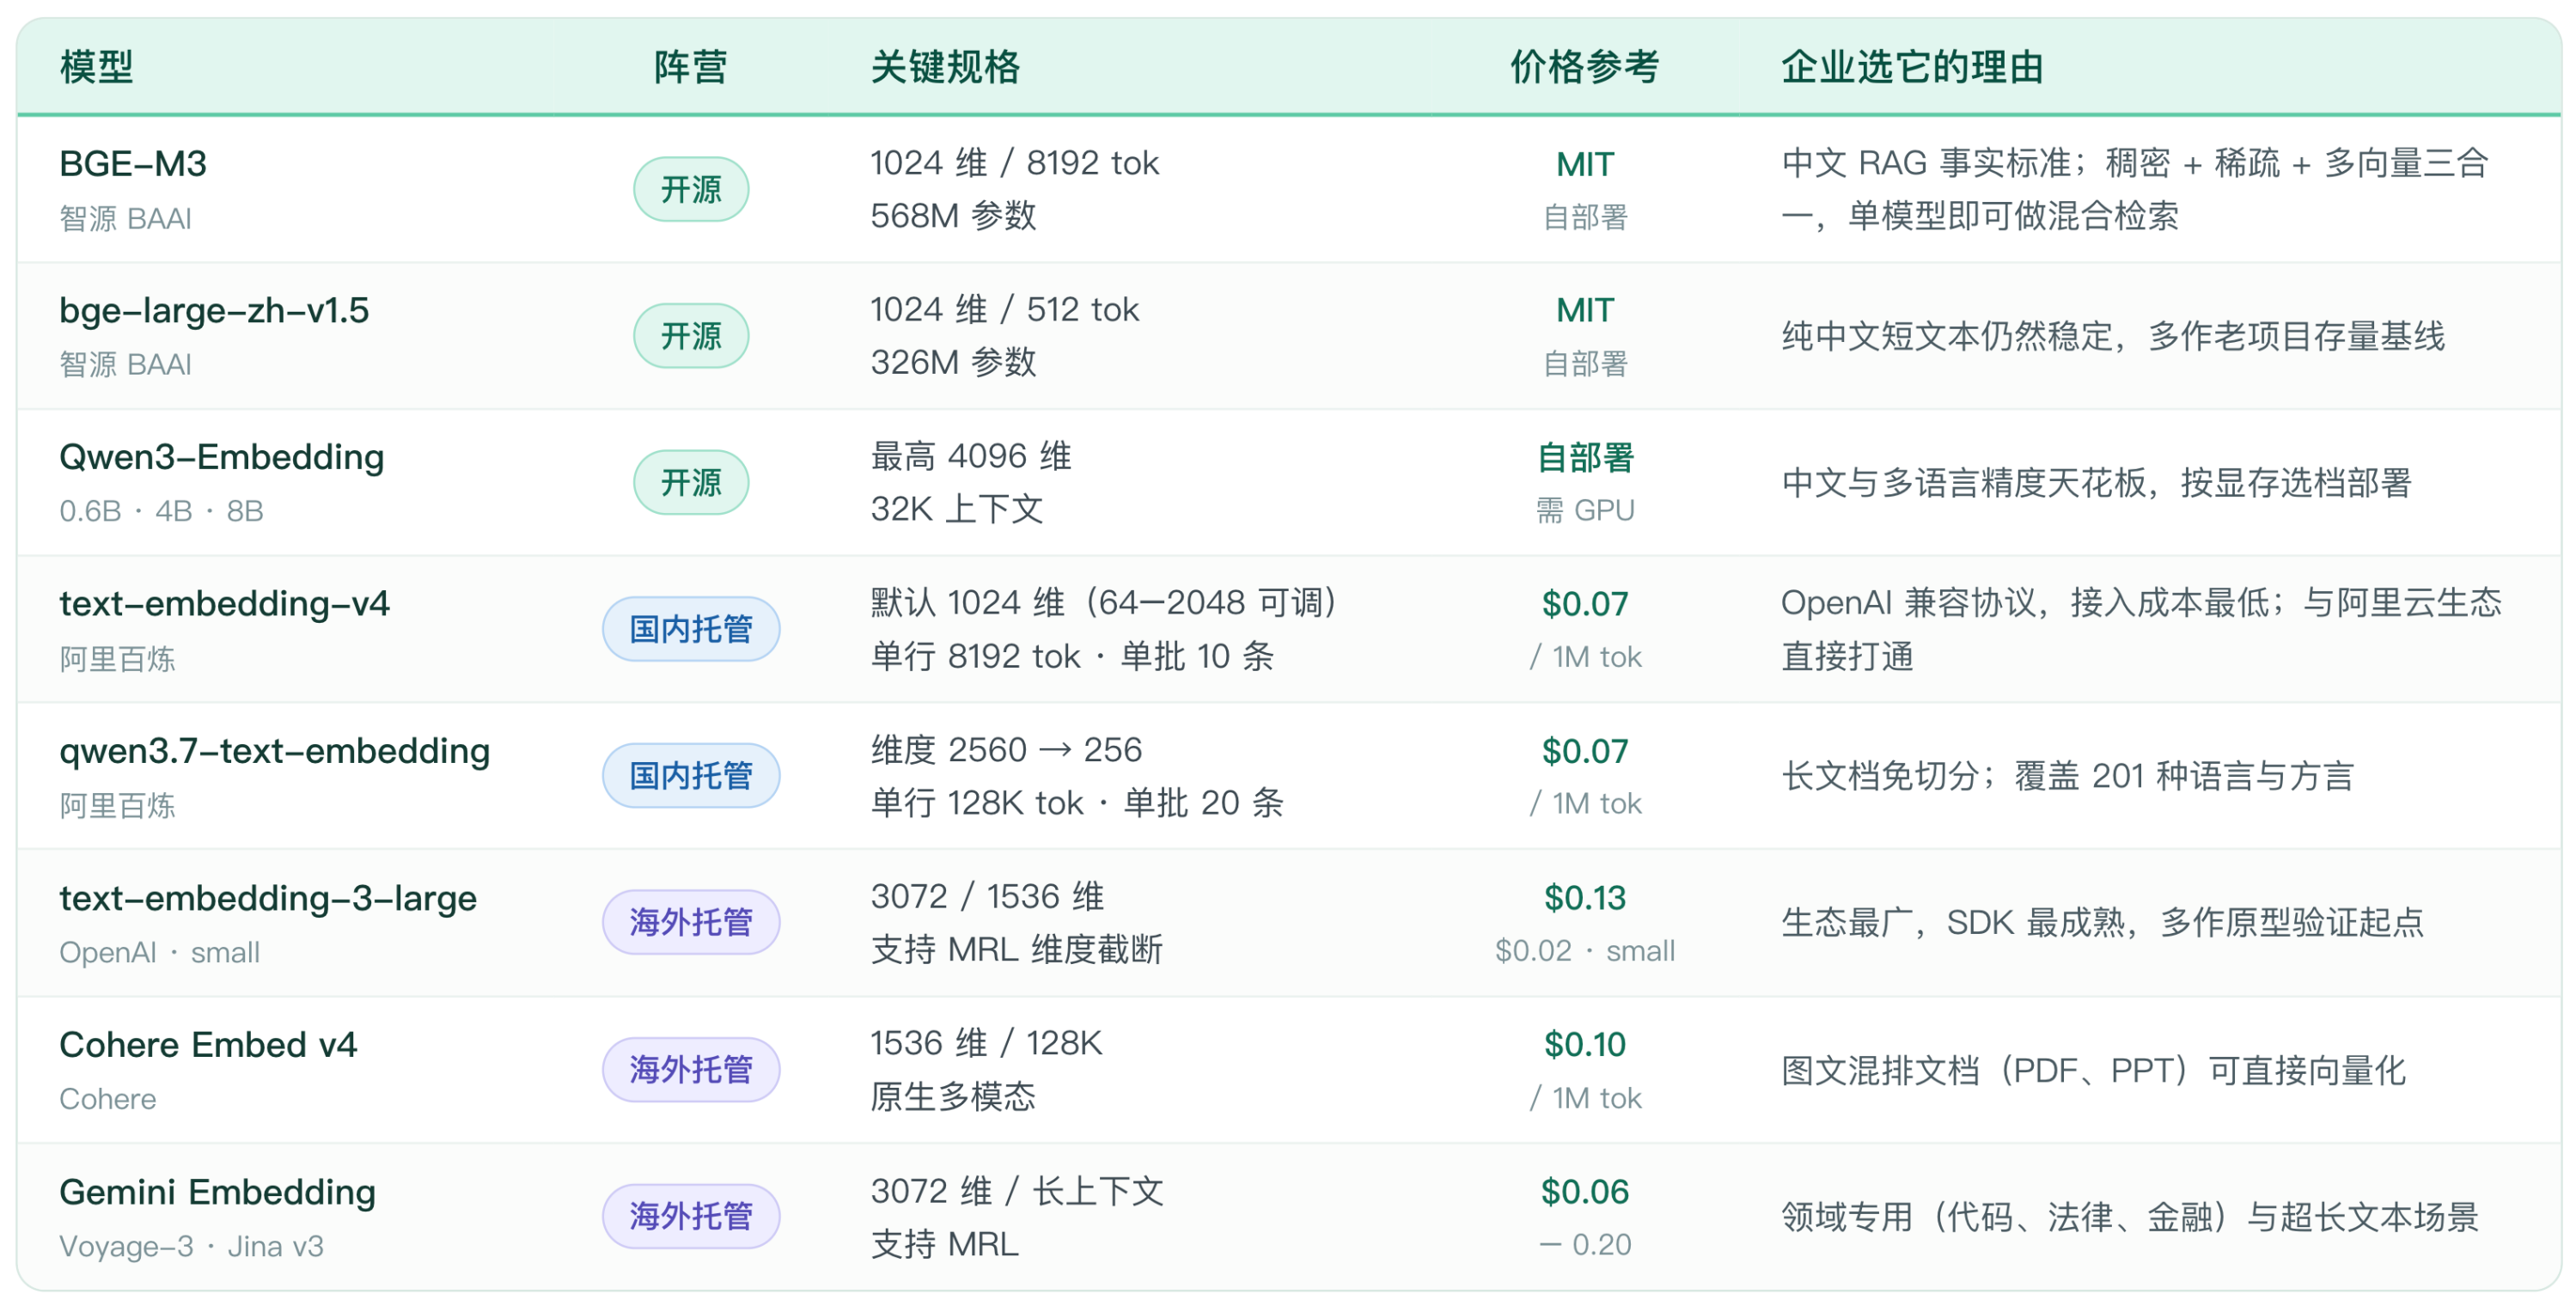

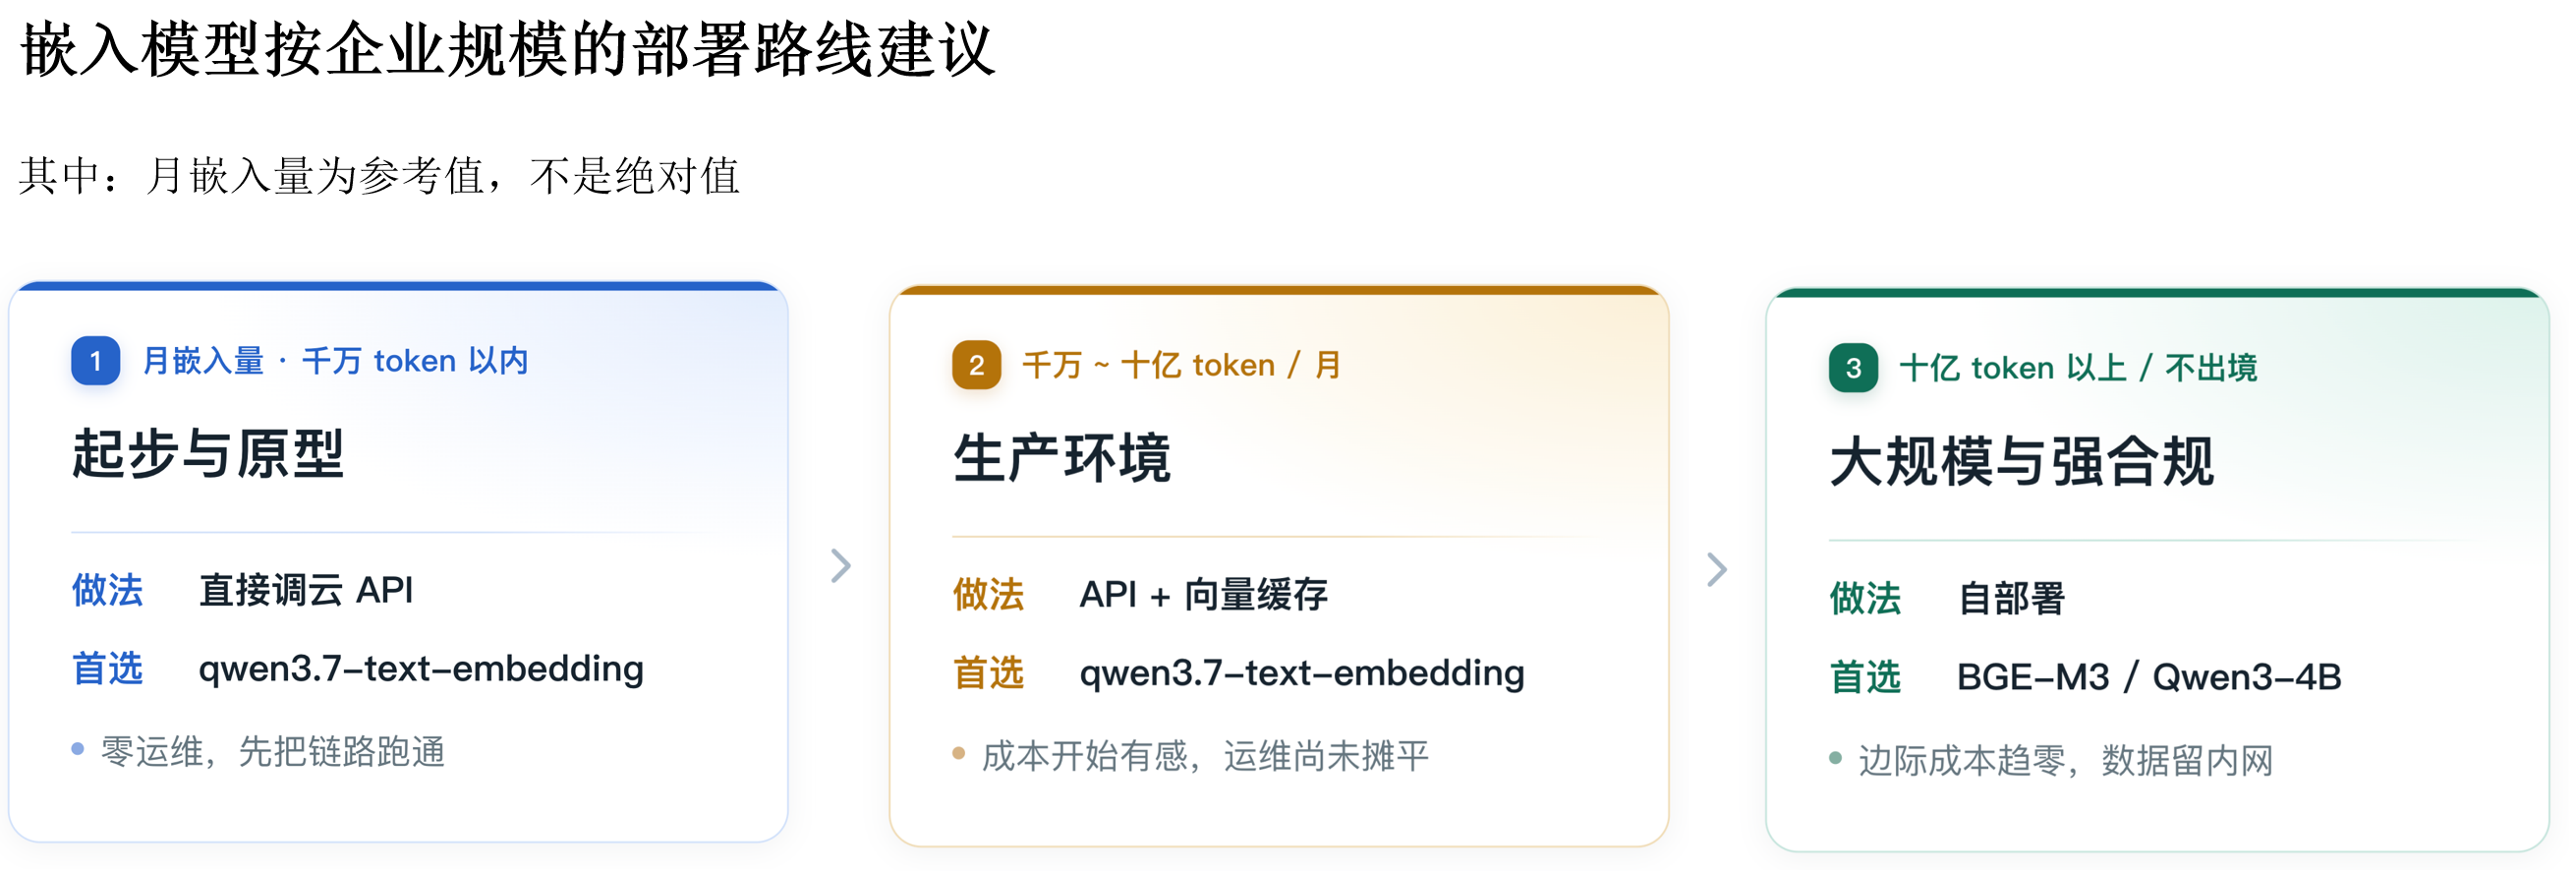

### 余弦相似度计算

In [8]:
import numpy as np
def cosine_similarity(vec1, vec2):
    """余弦相似度函数"""
    dot = np.dot(vec1, vec2)
    return dot / (np.linalg.norm(vec1) * np.linalg.norm(vec2))

### 阿里嵌入模型 DashScopeEmbeddings

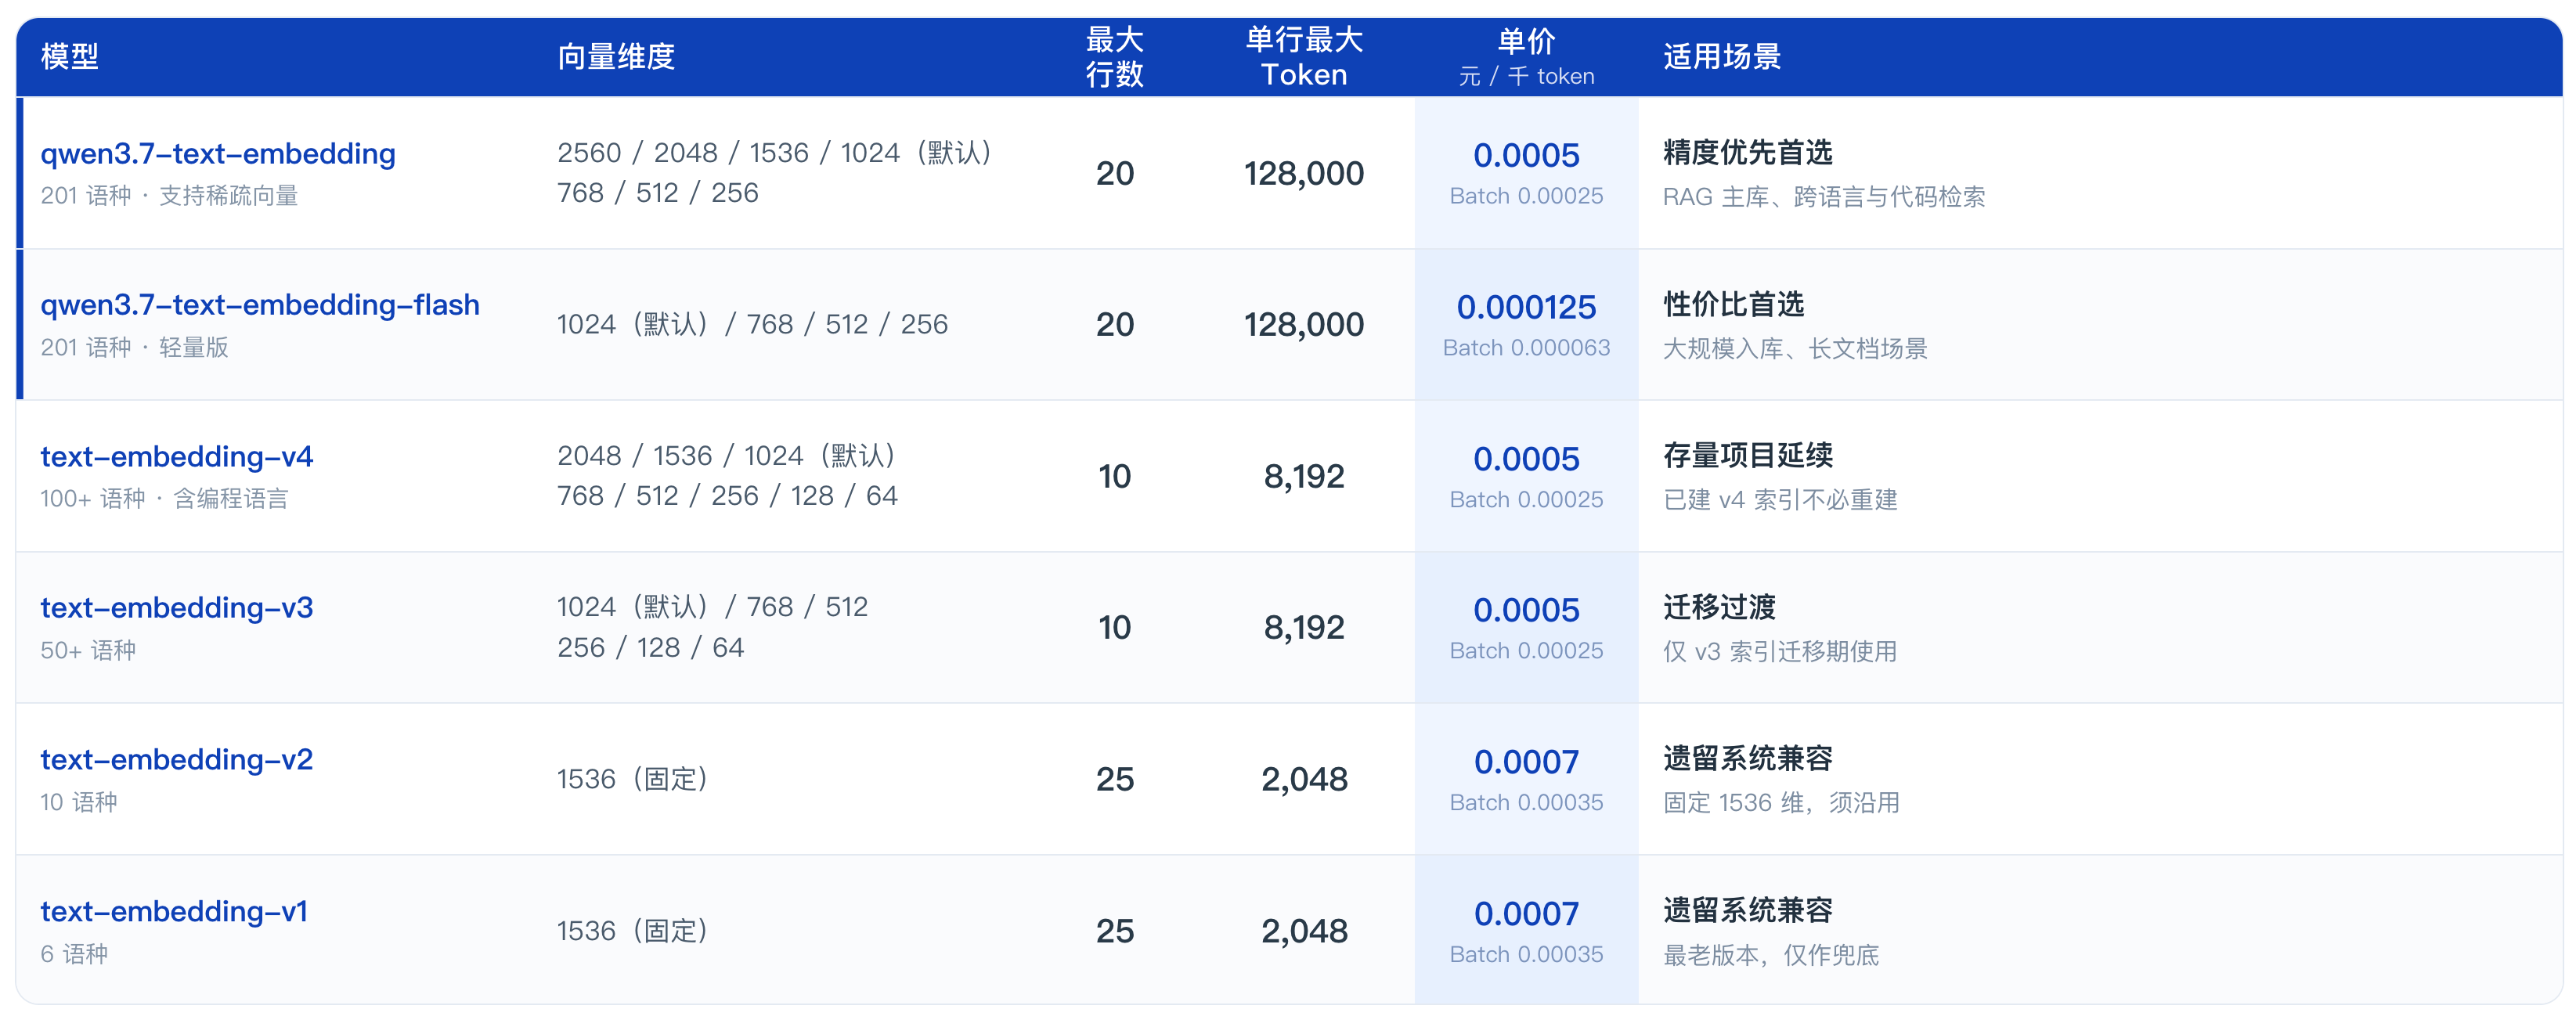

qwen嵌入模型对比：https://docs.bailian.console.aliyun.com/zh/model-studio/text-embedding-synchronous-api

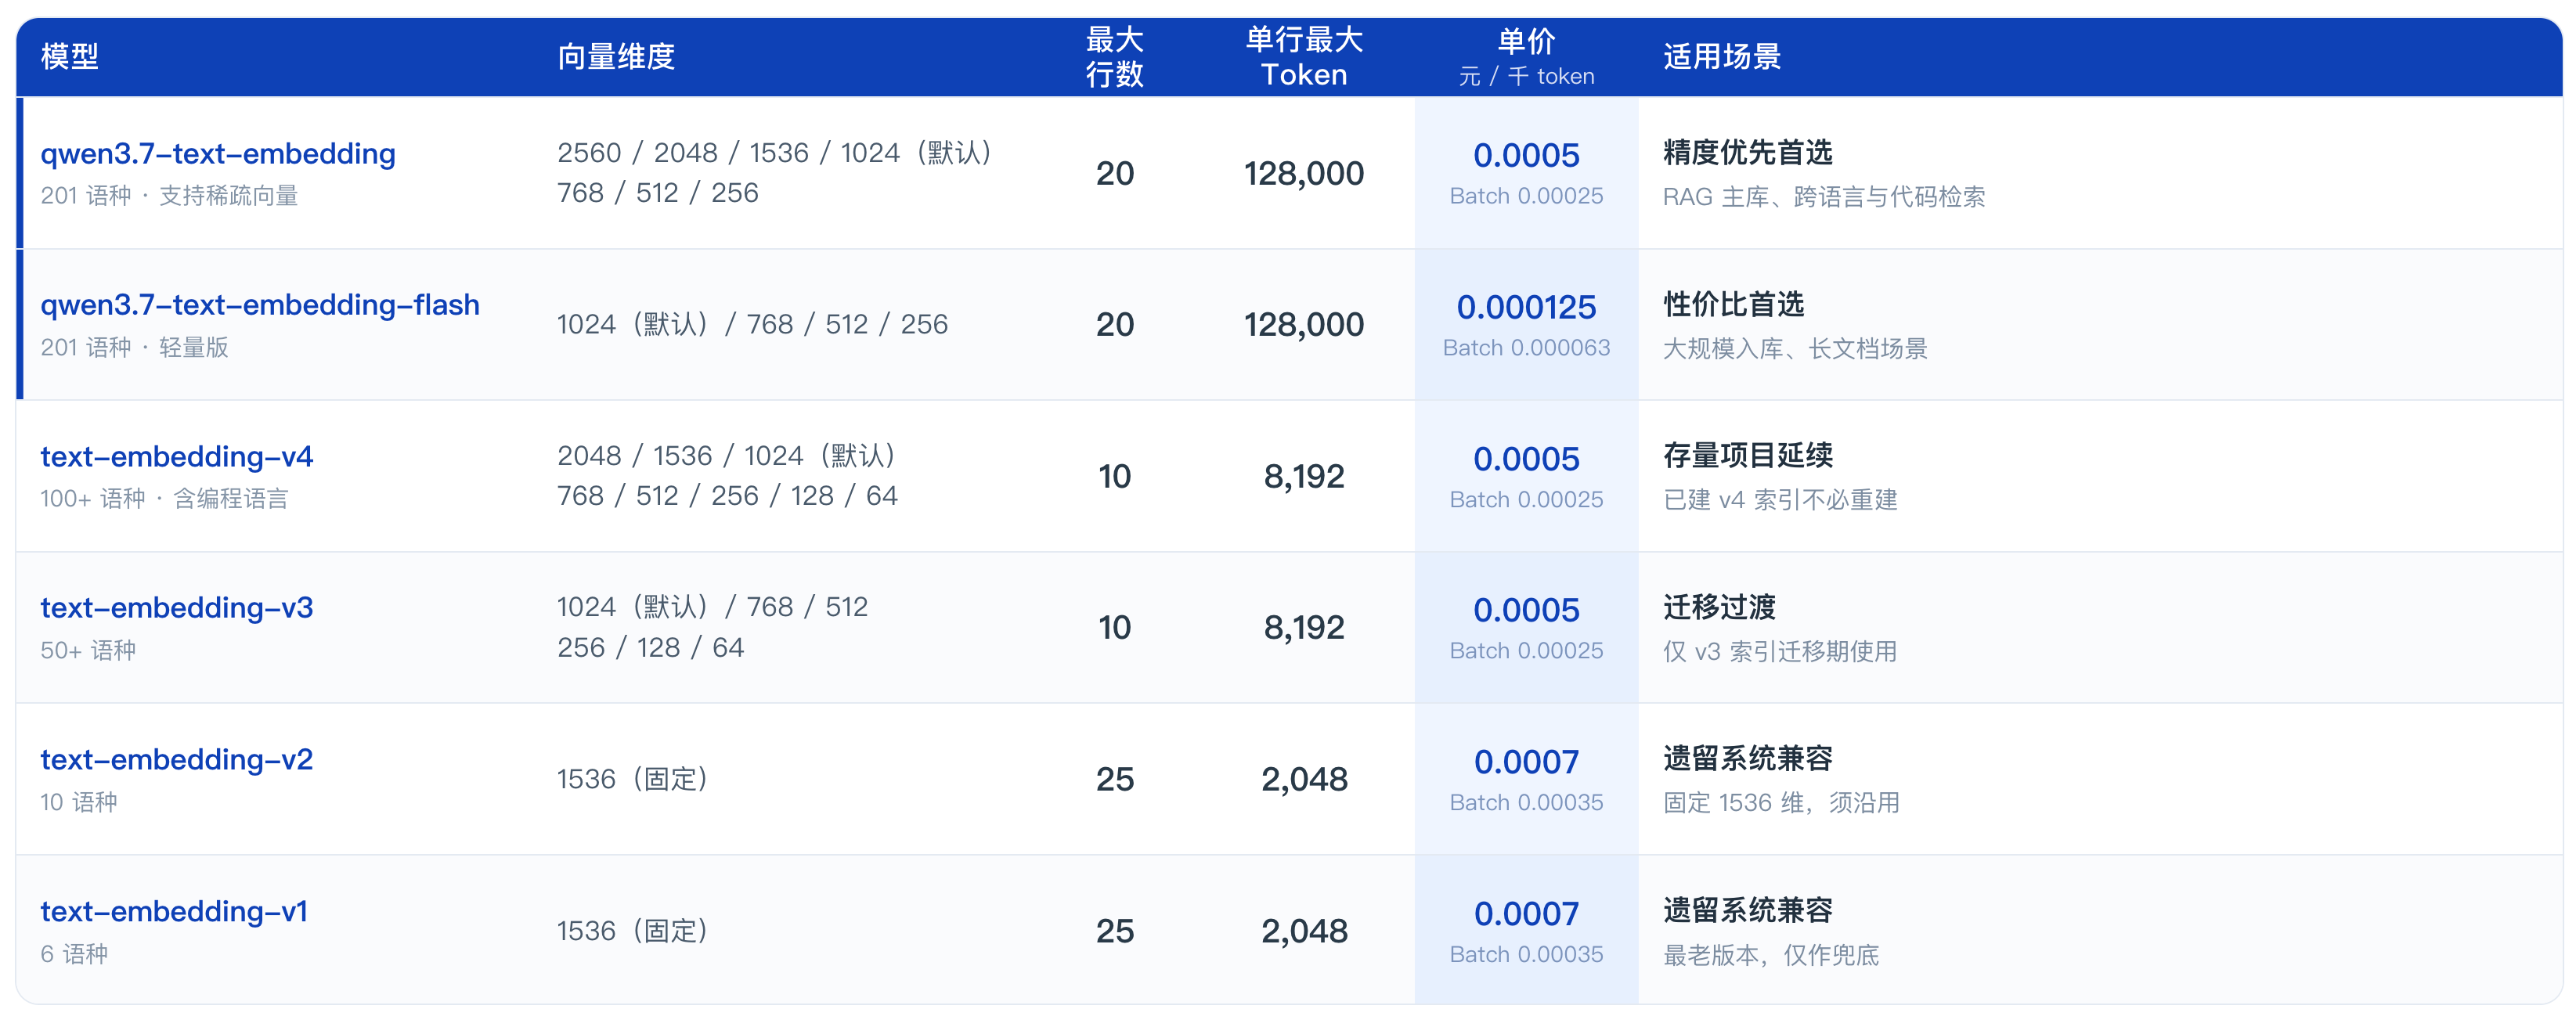

In [11]:
import os
from langchain_community.embeddings import DashScopeEmbeddings
embeddings = DashScopeEmbeddings(model="text-embedding-v4", dashscope_api_key=os.getenv("DASHSCOPE_API_KEY"))
# 向量化单条文本
text = "我爱上班"
vec = embeddings.embed_query(text)
print(f"单条向量维度：{len(vec)}")

# 向量化多条文本
texts = ["我要躺平", "我爱工作", "拒绝加班"]
vecs = embeddings.embed_documents(texts)
print(f"\n批量向量化: {len(vecs)} 条, 维度: {len(vecs[0])}")

print('==============衡量相似度===============')
for i, v in enumerate(vecs):
    similarity = cosine_similarity(vec, v)
    print(f"{texts[i]}:", similarity)

单条向量维度：1024

批量向量化: 3 条, 维度: 1024
==============衡量相似度===============
我要躺平: 0.40120064431301805
我爱工作: 0.8227559840016682
拒绝加班: 0.41688926472977117


### Ollma本地部署

安装依赖
```
pip install ollama
pip install langchain_ollama
```

下载bgm-m3
```
ollama pull bge-m3
ollama list
ollama bge-m3 "text"
```

In [10]:
from langchain_ollama import OllamaEmbeddings

embeddings = OllamaEmbeddings(
    model="bge-m3",
    dimensions=1024, # 可选：减少维度以节省存储
    # base_url="http://localhost:11434"
)

# 向量化单条文本
text = "我爱上班"
vec = embeddings.embed_query(text)
print(f"单条向量维度：{len(vec)}")

# 向量化多条文本
texts = ["我要躺平", "我爱工作", "拒绝加班"]
vecs = embeddings.embed_documents(texts)
print(f"\n批量向量化: {len(vecs)} 条, 维度: {len(vecs[0])}")

print('==============衡量相似度===============')
for i, v in enumerate(vecs):
    similarity = cosine_similarity(vec, v)
    print(f"{texts[i]}:", similarity)

单条向量维度：1024

批量向量化: 3 条, 维度: 1024
==============衡量相似度===============
我要躺平: 0.5433506479508465
我爱工作: 0.8985787111180602
拒绝加班: 0.6159745392212094
